This is the cutdown companion Jupyter Notebook of Chapter 5, Variational Quantum Eigensolver (VQE) Algorithm, of the second edition of the book titled: "Quantum Chemistry and Computing for the Curious: Illustrated with Python and Qiskit® code" and with ISBN-13: 978-1803243900. Copyright © 2026, Keeper L. Sharkey and Alain Chancé.

The following MIT license only applies to the code, and not to the text and images. The authors are not granting a license to replicate or reuse the text and images in the companion Jupyter notebook.

# MIT License

Copyright (c) 2026 Packt

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.


# 5. Variational Quantum Eigensolver (VQE) Algorithm

# Technical requirements
A companion Jupyter notebook for this chapter can be downloaded from GitHub at  https://github.com/PacktPublishing/Quantum-Chemistry-and-Computing-for-the-Curious-Second-Edition. For more information about how to install Qiskit, please refer to the IBM Install Qiskit documentation, https://quantum.cloud.ibm.com/docs/en/guides/install-qiskit, and in Robert Loredo's book [Loredo_Qiskit].

The companion Jupyter notebook automatically installs the following list of libraries:
*   Numerical Python (NumPy) [NumPy], an open-source Python library that is used in almost every field of science and engineering.
*   Qiskit [Qiskit], an open-source SDK for working with quantum computers at the level of pulses, circuits, and application modules.
*   Qiskit visualization support to enable the use of visualizations and Jupyter notebooks.
*   Qiskit Nature [Qiskit_Nature] [Qiskit_Nat_0], a unique platform to bridge the gap between natural sciences and quantum simulations.
*   Python-based Simulations of Chemistry Framework (PySCF) [PySCF], an open-source collection of electronic structure modules powered by Python.
*   Quantum Toolbox in Python (QuTiP) [QuTiP], a general framework for solving quantum mechanics problems such as systems composed of few-level quantum systems and harmonic oscillators.
*   Atomic Simulation Environment (ASE) [ASE_0], a set of tools and Python modules for setting up, manipulating, running, visualizing, and analyzing atomistic simulations. The code is freely available under the GNU LGPL license.
*   PyQMC [PyQMC], a Python module that implements real-space quantum Monte Carlo techniques. It is primarily meant to interoperate with PySCF.
*   h5py [h5py] package, a Pythonic interface to the HDF5 binary data format.
*   SciPy, [SciPy], a Python module that contains a large number of probability distributions, summary and frequency statistics, correlation functions and statistical tests, masked statistics, kernel density estimation, quasi-Monte Carlo functionality, and more.

# Updates in the Second Edition
## Updates in 5.1.3. Quantum phase estimation (QPE)
### The number of unitary qubits must match the number of state preparation qubits
### QPE with reference-guided phase unwrapping
## Updates in 5.1.4. Description of the VQE algorithm
### QuantumCircuit.num_qubits is read-only

## Temporary fix in Qiskit Nature file qeom.py - Use at your own risk

In [1]:
pip install qiskit-nature

Note: you may need to restart the kernel to use updated packages.


In [2]:
#----------------------------------------------------------------------------------------------------
# Temporary fix in Qiskit Nature file qeom.py — Use at your own risk.
#
# **Warning**
# Like any other Apache 2 licensed code, you are free to use `qiskit_algorithms` and `qiskit_nature` 
# libraries or/and extend them, but please be aware that it is under your own risk. 
# See disclaimer in readme,
# https://github.com/qiskit-community/qiskit-algorithms?tab=readme-ov-file#qiskit-algorithms
#
# In Qiskit 2.x, BaseEstimator no longer exists.
#
# The following snippet tries to execute the following command:
# 
#   from qiskit_nature.second_q.algorithms.ground_state_solvers import GroundStateEigensolver
# 
# If it fails, then it tries to comment out the following line:
# 
#   from qiskit.primitives import BaseEstimator
# 
# in the following file, if it can find it:
#
# qiskit_nature/second_q/algorithms/excited_states_solvers/qeom.py`
#----------------------------------------------------------------------------------------------------
apply_patch = False
try:
    from qiskit_nature.second_q.algorithms.ground_state_solvers import GroundStateEigensolver
except Exception as e:
    print(f"Error trying import GroundStateEigensolver: {e}")
    apply_patch = True

if apply_patch:
    import os
    import site
    import re
    from pathlib import Path
    
    sitepackages = site.getsitepackages()
    path = Path(sitepackages[0]) / "qiskit_nature" / "second_q" / "algorithms" / "excited_states_solvers" / "qeom.py"
    
    if os.path.isfile(path):
        text = path.read_text()
        pattern = r"^\s*from qiskit\.primitives import BaseEstimator\s*$"
        
        if re.search(pattern, text, flags=re.MULTILINE):
            print("Patching qeom.py...")
            text = re.sub(
                pattern,
                "# from qiskit.primitives import BaseEstimator",
                text,
                flags=re.MULTILINE
            )
            path.write_text(text)
            print("Patch applied ✅")
        else:
            print("Patch already applied or line not found 👍")

Error trying import GroundStateEigensolver: cannot import name 'BaseEstimator' from 'qiskit.primitives' (/home/alain/miniconda3/lib/python3.13/site-packages/qiskit/primitives/__init__.py)
Patching qeom.py...
Patch applied ✅


## Installing NumPy, and Qiskit and importing various modules
### Install NumPy with the following command:

In [3]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit with the following command:

In [4]:
pip install qiskit

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit visualization support with the following command:

In [5]:
pip install 'qiskit[visualization]'

Note: you may need to restart the kernel to use updated packages.


## Install qiskit aer with the following command:

In [6]:
pip install qiskit-aer

Note: you may need to restart the kernel to use updated packages.


### Install qiskit.utils with the following command:

In [7]:
pip install qiskit.utils

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for qiskit.utils: filename=qiskit_utils-1.2.1-py3-none-any.whl size=6593 sha256=c4c83426c0c5ea67fbf371abead8dafd8ed6322272400a7cb029320851836ddd
  Stored in directory: /home/alain/.cache/pip/wheels/74/34/71/d03f0af9c0cda2eaacc25d287e80fac5b68b492f00d44c84fa
Successfully built qiskit.utils
Note: you may need to restart the kernel to use updated packages.


### Install Qiskit Nature with the following command:

In [8]:
pip install qiskit-nature

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit Algorithms with the following command:

In [9]:
pip install qiskit_algorithms

Note: you may need to restart the kernel to use updated packages.


### Install PySCF with the following command:

In [10]:
pip install pyscf

Note: you may need to restart the kernel to use updated packages.


### Install QuTiP with the following command:

In [11]:
pip install qutip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.9/32.9 MB 9.4 MB/s  0:00:03m0:00:0100:01m
Note: you may need to restart the kernel to use updated packages.


### Install ASE with the following command:

In [12]:
pip install ase

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 29.2 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


### Install PyQMC with the following command:

In [13]:
pip install pyqmc --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 28.7 MB/s  0:00:00m0:00:010:01
  Attempting uninstall: pandas
    Found existing installation: pandas 3.0.1
    Uninstalling pandas-3.0.1:
      Successfully uninstalled pandas-3.0.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pyqmc]]
Note: you may need to restart the kernel to use updated packages.


### Install h5py with the following command:

In [14]:
pip install h5py

Note: you may need to restart the kernel to use updated packages.


### Install SciPy with the following command:

In [15]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.


### Import NumPy with the following command:

In [16]:
import numpy as np

### Import Matplotlib with the following command:

In [17]:
import matplotlib.pyplot as plt

### Import Qiskit Runtime primitives with the following commands:

In [18]:
# Import Qiskit Runtime primitives
from qiskit.primitives import BaseSamplerV2 as BaseSampler, StatevectorSampler as Sampler
from qiskit.primitives import BaseEstimatorV2 as BaseEstimator, StatevectorEstimator as Estimator

### Import the required functions and class methods with the following commands:

In [19]:
from qiskit.visualization import array_to_latex, plot_bloch_vector, plot_bloch_multivector, plot_state_qsphere, plot_state_city
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit, transpile
import qiskit.quantum_info as qi
from qiskit.circuit.library import Initialize
from qiskit.quantum_info import SparsePauliOp

from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

## Import qiskit.aer and AerSimulator with the following commands:

In [20]:
import qiskit_aer
from qiskit_aer import AerSimulator

### Import the Qiskit Nature libraries with the following commands:

In [21]:
from qiskit_nature.second_q.formats.molecule_info import MoleculeInfo
from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.drivers import PySCFDriver

from qiskit_nature.second_q.mappers import ParityMapper, JordanWignerMapper, BravyiKitaevMapper
from qiskit_nature.second_q.properties import ParticleNumber
from qiskit_nature.second_q.transformers import ActiveSpaceTransformer, FreezeCoreTransformer
from qiskit_nature.second_q.operators import FermionicOp
from qiskit_nature.second_q.operators import ElectronicIntegrals

from qiskit_nature import settings

### Import various algorithms with the following commands:

In [22]:
from qiskit_algorithms import PhaseEstimation

from qiskit_algorithms.optimizers import SLSQP, SPSA, QNSPSA
from qiskit_nature.second_q.circuit.library import UCCSD, HartreeFock

from qiskit_algorithms.minimum_eigensolvers import NumPyMinimumEigensolver, VQE
from qiskit_nature.second_q.algorithms.ground_state_solvers import GroundStateEigensolver

from qiskit.circuit.library import n_local
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp

from functools import partial as apply_variation

### Import the PySCF gto and scf libraries with the following command:

In [23]:
from pyscf import gto, scf

### Import the PyQMC API library with the following command:

In [24]:
import pyqmc.api as pyq

### Import h5py with the following command:

In [25]:
import h5py

### Import the ASE libraries, the Atoms object, molecular data, and visualizations with the following commands:

In [26]:
from ase import Atoms
from ase.build import molecule
from ase.visualize import view

### Import the math libraries with the following commands:

In [27]:
import cmath
import math

### Import Python’s statistical functions provided by the SciPy package with the following command:

In [28]:
import scipy.stats as stats

### Import QuTiP with the following command:

In [29]:
import qutip

### Import time and datetime with the following command:

In [30]:
import time, datetime

### Import pandas and os.path with the following commands:

In [31]:
import pandas as pd
import os.path

### Import warnings and suppress SparseEfficiencyWarning with the following commands:

In [ ]:
import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

### Suppress H5pyDeprecationWarning with the following commands:

In [ ]:
warnings.filterwarnings(
    "ignore",
    message="Creating a dataset without passing data or dtype"
)

# 5.1. Variational method
## 5.1.1. The Ritz variational theorem

## 5.1.2. Variational Monte Carlo methods

In [32]:
def p(x):
  if x < 0:
    y = 0
  else:
    y = np.exp(-x)
  return(y)

In [33]:
n = 10000 # Size of the Markov chain stationary distribution

# Use np.linspace to create an array of n numbers between 0 and n
index = np.linspace(0, n, num=n)
x = np.linspace(0, n, num=n)

x[0] = 3     # Initialize to 3
for i in range(1, n):
  current_x = x[i-1]

  # We add a N(0,1) random number to x
  proposed_x = current_x + stats.norm.rvs(loc=0, scale=1, size=1, random_state=None)

  A = min(1, p(proposed_x)/p(current_x))

  r = np.random.uniform(0,1) # Generate a uniform random number in [0, 1]

  if r < A:
    x[i] = proposed_x[0]    # Accept move with probabilty min(1,A)
  else:
    x[i] = current_x        # Otherwise "reject" move, and stay where we are

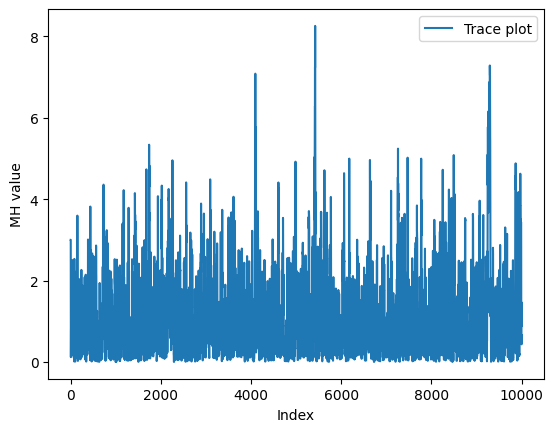

In [34]:
plt.plot(index, x, label="Trace plot")
plt.xlabel('Index')
plt.ylabel('MH value')
plt.legend()
plt.show()

In [35]:
q25, q75 = np.percentile(x, [25, 75])
bin_width = 2 * (q75 - q25) * len(x) ** (-1/3)
bins = round((x.max() - x.min()) / bin_width)
print("Freedman–Diaconis number of bins:", bins)

Freedman–Diaconis number of bins: 78


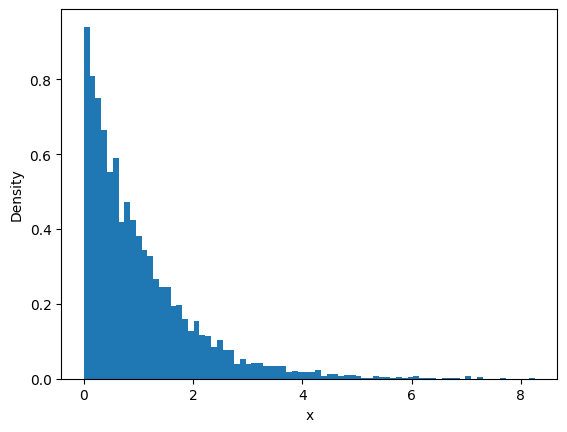

In [36]:
plt.hist(x, density=True, bins=bins)
plt.ylabel('Density')
plt.xlabel('x');

In [37]:
def run_PySCF(info_dict, pyqmc=True, show=True):
  # Reset the files
  for fname in ['mf.hdf5','optimized_wf.hdf5','vmc_data.hdf5','dmc.hdf5']:
    if os.path.isfile(fname):
        os.remove(fname)
  
  atoms = info_dict['atoms']
  coords = info_dict['coords']
  charge = info_dict['charge']
  multiplicity = info_dict['multiplicity']
  atom_pair = info_dict['atom_pair']

  s = ''
  k = 0
  for atom in atoms:
    s += atoms[k] + ' ' + str(coords[k][0]) + ' ' + str(coords[k][1]) + ' ' + str(coords[k][2]) + '; '
    k += 1
  s = s[0:-2]
  
  mol_PySCF = gto.M(atom = s)
  
  mf = scf.RHF(mol_PySCF)
  mf.chkfile = "mf.hdf5"
  
  conv, e, mo_e, mo, mo_occ = scf.hf.kernel(mf)
  if show:
    if conv:
      print("PySCF restricted HF (RHF) converged ground-state energy: {:.12f}".format(e))
    else:
      print("PySCF restricted HF (RHF) ground-state computation failed to converge")

  if pyqmc:
    pyq.OPTIMIZE("mf.hdf5",# Construct a Slater-Jastrow wave function from the pyscf output
      "optimized_wf.hdf5", # Store optimized parameters in this file.
      nconfig=100,         # Optimize using this many Monte Carlo samples/configurations
      max_iterations=4,    # 4 optimization steps
      verbose=False)

    with h5py.File("optimized_wf.hdf5") as f:
      iter = f['iteration']
      energy = f['energy']
      error = f['energy_error']
      l = energy.shape[0]
      e = energy[l-1]
      err = error[l-1]
      if show:
        if err < 0.1:
          print("Iteration, Energy, Error")
          for k in iter:
            print("{}:         {:.4f} {:.4f}".format(k, energy[k], error[k]))
          print("PyQMC Monte Carlo converged ground-state energy: {:.12f}, error: {:.4f}".format(e, err))
        else:
          print("PyQMC Monte Carlo failed to converge")

  return conv, e

## 5.1.3. Quantum Phase Estimation (QPE)

In [38]:
def U(theta):
    qc = QuantumCircuit(1)
    qc.p(2 * np.pi * theta, 0)   # Phase gate
    return qc

In [39]:
def do_qpe(unitary, nqubits, state_preparation):
    if unitary.num_qubits != state_preparation.num_qubits:
        print(
            f"Number of unitary qubits: {unitary.num_qubits} "
            f"does not match number of state preparation qubits: {state_preparation.num_qubits}"
        )
    pe = PhaseEstimation(
        num_evaluation_qubits=nqubits,
        sampler=Sampler()
    )
    result = pe.estimate(unitary, state_preparation)
    return result.phase

In [40]:
def test_do_qpe(theta, nqubits=3):
    unitary = U(theta)
    state_prep = QuantumCircuit(unitary.num_qubits)
    state_prep.x(0)  # |1> (common for simple demos)
    phase = do_qpe(unitary, nqubits=nqubits, state_preparation=state_prep)
    print("theta:", theta)
    print(f"Number of qubits: {nqubits}, QPE phase estimate: {phase}")

In [41]:
theta = 1/2 + 1/4 + 1/8
test_do_qpe(theta, nqubits=3)

theta: 0.875
Number of qubits: 3, QPE phase estimate: 0.875


In [42]:
theta = 1/2 + 1/4 + 1/8 + 1/16 + 1/32 + 1/64 + 1/128 + 1/256
test_do_qpe(theta, nqubits=8)

theta: 0.99609375
Number of qubits: 8, QPE phase estimate: 0.99609375


### QPE with reference-guided phase unwrapping

In [43]:
def unwrap_energy_reference_guided(
    phase,
    t,
    reference_energy=None,
    identity_shift=0.0,
    k_center=None,
    k_window=2,
    verbose=False,
    show=True
):
    """
    Unified, reference-guided phase → energy reconstruction.

    Searches over:
        phase' ∈ {φ, 1−φ}
        sign  ∈ {−, +}
        k     ∈ [k_center - k_window, ..., k_center + k_window]

    and selects the candidate that:
        - minimizes |E - reference_energy| if reference_energy is given
        - otherwise, minimizes E (ground-state heuristic)
    """

    # --- Effective reference (remove identity shift once) ---
    if reference_energy is not None:
        effective_ref = reference_energy - identity_shift
    else:
        effective_ref = None

    # --- If no k_center is provided, use a naive prediction from the reference ---
    if k_center is None and effective_ref is not None:
        k_center = int(np.round((effective_ref * t) / (2 * np.pi) - phase))
    elif k_center is None:
        # If we truly have no reference, just center around k=0
        k_center = 0

    # --- Candidate phases (standard and "1-φ" branch) ---
    phase_candidates = {
        "std": phase,
        "alt": 1 - phase,
    }

    best_key = None
    best_energy = None
    best_cost = None

    if verbose:
        print("\nUnified unwrapping diagnostics:")
        print(f"phase: {phase:.6f}, t: {t:.6f}")
        print(f"identity_shift: {identity_shift:.6f}")
        print(f"k_center: {k_center}, k_window: {k_window}")
        if reference_energy is not None:
            print(f"reference_energy: {reference_energy:.6f}")

    # --- Scan over k, branch, and sign ---
    for k in range(k_center - k_window, k_center + k_window + 1):
        for branch_name, phase_base in phase_candidates.items():
            phase_unwrapped = phase_base + k

            # Two sign conventions
            E_minus = identity_shift - (2 * np.pi * phase_unwrapped) / t
            E_plus  = identity_shift + (2 * np.pi * phase_unwrapped) / t

            for sign_name, E in [("minus", E_minus), ("plus", E_plus)]:
                key = f"k={k:+d}, {branch_name}_{sign_name}"

                if reference_energy is None:
                    # Ground-state heuristic: prefer lowest energy
                    cost = E
                else:
                    cost = abs(E - reference_energy)

                if verbose:
                    print(f"{key:20s} -> E = {E:.6f} Ha, cost = {cost:.6f}")

                if best_cost is None or cost < best_cost:
                    best_cost = cost
                    best_energy = E
                    best_key = key

    if show:
        print(f"\nChosen candidate: {best_key}")
        print(f"Chosen energy:   {best_energy:.6f} Ha")

    return best_energy

### Orchestrating the QPE workflow

In [44]:
def run_qpe(problem, qubit_op, mapper, n_ancillae=3, t=None,
            reference_energy=None, show=True):
    """
    Run QPE with automatic evolution time selection.
    Args:
        problem: ElectronicStructureProblem
        qubit_op, a qubit operator returned by the function fermion_to_qubit()
        mapper, a mapper returned by the function fermion_to_qubit(), either “Jordan-Wigner” or “Parity” or “Bravyi-Kitaev”
        n_ancillae: Number of evaluation qubits
        t: Evolution time (auto if None)
        reference_energy: Reference energy
        show: set to True by default to display intermediate results
    """

    # --- Identity shift ---
    identity_shift = 0.0
    for pauli, coeff in zip(qubit_op.paulis, qubit_op.coeffs):
        if pauli.to_label() == 'I' * qubit_op.num_qubits:
            identity_shift = coeff.real
            break

    H_no_I = qubit_op - identity_shift * SparsePauliOp('I' * qubit_op.num_qubits)

    # --- Norm estimate ---
    spectral_norm = np.sum(np.abs(H_no_I.coeffs))
    if t is None:
        t = np.pi / spectral_norm
    t = min(max(t, 0.1), 10.0)

    U = PauliEvolutionGate(H_no_I, time=t)

    state_prep = HartreeFock(
        problem.num_spatial_orbitals,
        problem.num_particles,
        mapper
    )

    if show:
        print("\nrun_qpe diagnostics:")
        print("Hamiltonian qubits:", qubit_op.num_qubits)
        print("Identity shift:", identity_shift)
        print("Spectral norm:", spectral_norm)
        print("Evolution time t:", t)

    phase = do_qpe(U, nqubits=n_ancillae, state_preparation=state_prep)

    # Unified unwrapping (optionally with a k_center from the reference)
    energy = unwrap_energy_reference_guided(
        phase=phase,
        t=t,
        reference_energy=reference_energy,
        identity_shift=identity_shift,
        k_center=None,   # or use predict_k_from_reference and pass k_center
        k_window=2,
        verbose=False,
        show=True
    )

    if show:
        print(f"\nMeasured phase: {phase}")
        print(f"Ground state energy from QPE: {energy:.6f} Ha")

    return energy

## 5.1.4. Description of the VQE algorithm

### Trial wavefunctions
### Setting-up the VQE solver

In [45]:
numpy_solver = NumPyMinimumEigensolver()

In [46]:
def create_tl_circuit(num_qubits):
    tl_circuit = n_local(
        num_qubits=num_qubits,   # REQUIRED now
        rotation_blocks=['h', 'rx'],
        entanglement_blocks='cz',
        entanglement='full',
        reps=2,
        parameter_prefix='y'
    )
    return tl_circuit

In [47]:
def create_vqe_tl_solver(num_qubits, maxiter=100):
    estimator = Estimator()
    optimizer = SPSA(maxiter=maxiter)
    tl_circuit = create_tl_circuit(num_qubits)
    vqe_tl_solver = VQE(estimator, tl_circuit, optimizer)
    return vqe_tl_solver

In [48]:
def create_vqe_tl_QNSPSA_solver(num_qubits, maxiter=200, learning_rate=0.01, perturbation=0.7, loss=[]):
    tl_circuit = create_tl_circuit(num_qubits)

    def qnspsa_callback(nfev, x, fx, stepsize, accepted):
        loss.append(fx)
    
    fidelity = QNSPSA.get_fidelity(tl_circuit, sampler=Sampler())
    qnspsa = QNSPSA(fidelity, maxiter=maxiter, learning_rate=learning_rate, perturbation=perturbation, callback=qnspsa_callback)
    
    estimator = Estimator()
    vqe_tl_QNSPSA_solver = VQE(estimator, tl_circuit, optimizer=qnspsa)
    
    return vqe_tl_QNSPSA_solver

In [49]:
def run_vqe(name_solver, problem, mapper, num_qubits, maxiter=200, learning_rate=0.01, perturbation=0.7, loss=[], show=False):
    match name_solver:
        case "NumPy exact solver":
            solver = numpy_solver
        case "vqe_tl_solver":
            solver = create_vqe_tl_solver(num_qubits, maxiter=maxiter)
        case "vqe_tl_QNSPSA_solver":
            solver = create_vqe_tl_QNSPSA_solver(num_qubits, 
                                                 maxiter=maxiter, 
                                                 learning_rate=learning_rate, 
                                                 perturbation=perturbation,
                                                 loss=loss,
                                                )
        case "UCCSD ansatz":
            ansatz = UCCSD(
                problem.num_spatial_orbitals,
                problem.num_particles,
                mapper,
                initial_state=HartreeFock(problem.num_spatial_orbitals,problem.num_particles,mapper),
            )
            solver = VQE(Estimator(), ansatz, SLSQP())
    
    calc = GroundStateEigensolver(mapper, solver)
    main_operator, _ = calc.get_qubit_operators(problem)
    start = time.time()
    ground_state = calc.solve(problem)
    elapsed = str(datetime.timedelta(seconds = time.time()-start))
    
    if show:
        print(f"Running the VQE using the {name_solver}")
        print(f"run_vqe - main_operator.num_qubits: {main_operator.num_qubits}")
        print(f"Elapsed time: {elapsed}\n")
        print(ground_state)

    return ground_state

# 5.2. Example chemical calculations

### Sampling the potential energy surface (PES)

In [50]:
# Sampling the potential energy surface
_EPS = 1e-2 # Global variable used to chop small numbers to zero
def bopes(info_dict, mapper_name, num_electrons, num_spatial_orbitals, two_qubit_reduction, z2symmetry_reduction,
          name_solver, perturbation_steps, mapper, show_VQE=False, show=True):
  
  atoms = info_dict['atoms']
  coords = info_dict['coords']
  charge = info_dict['charge']
  multiplicity = info_dict['multiplicity']
  atom_pair = info_dict['atom_pair']

  size = len(perturbation_steps)
  
  energy = np.empty(size)

  x0 = coords[atom_pair[0]][0]
  y0 = coords[atom_pair[0]][1]
  z0 = coords[atom_pair[0]][2]
  if show:
    print("x0, y0, z0 :", x0, y0, z0)
  
  x1 = coords[atom_pair[1]][0]
  y1 = coords[atom_pair[1]][1]
  z1 = coords[atom_pair[1]][2]
  if show:
    print("x1, y1, z1 :", x1, y1, z1)
    
  if abs(x1 - x0) > _EPS:
    # Find the equation of a straight line y = m*x + p that crosses the points of the atom pair
    m = (y1 - y0)/(x1 - x0)
    p = y0 - m*x0  
  
  for k in range(size):
    if (abs(x0)<_EPS and abs(y0)<_EPS):
      z0_new = z0 + perturbation_steps[k]
      coords_new = []
      for l in range(len(coords)):
        if l == atom_pair[0]:
          coords_new.append((0.0, 0.0, z0_new))
        else:
          coords_new.append(coords[l])

    elif (abs(z0)<_EPS and abs(z1)<_EPS):
      x0_new = x0 + perturbation_steps[k]
      y0_new = m*x0_new + p
      coords_new = []
      for l in range(len(coords)):
        if l == atom_pair[0]:
          coords_new.append((x0_new, y0_new, 0.0))
        else:
          coords_new.append(coords[l])
    
    info_dict_new={'atoms':atoms, 'coords':coords_new, 'charge':charge, 
                  'multiplicity':multiplicity, 'atom_pair':atom_pair}
    
    fermionic_hamiltonian, num_particles, num_spin_orbitals, qubit_op, mapper, ground_state = \
    solve_ground_state(
        info_dict_new,
        mapper_name=mapper_name,
        num_electrons=num_electrons,
        num_spatial_orbitals=num_spatial_orbitals,
        two_qubit_reduction=two_qubit_reduction,
        z2symmetry_reduction=z2symmetry_reduction, 
        name_solver=name_solver,
        show_VQE=show_VQE,
        pyqmc=False)
    
    energy[k] = ground_state.total_energies[0]
    
  return perturbation_steps, energy

In [51]:
def get_particle_number(problem, show=True):
  # https://qiskit.org/documentation/nature/stubs/qiskit_nature.second_q.problems.ElectronicStructureProblem.num_spin_orbitals.html
  num_spin_orbitals = problem.num_spin_orbitals
  num_particles = problem.num_particles
  if show:
    print("Number of particles: {}".format(num_particles))
    print("Number of spin orbitals: {}".format(num_spin_orbitals))
  return num_particles, num_spin_orbitals

In [52]:
def fermion_to_qubit(problem, 
                     second_q_op,
                     mapper_name,
                     truncate=20,
                     two_qubit_reduction=False,
                     z2symmetry_reduction=None,
                     show=True): 
  if show:
    print("Qubit Hamiltonian operator")
    print("{} transformation ". format(mapper_name))

  match mapper_name:
    case "Jordan-Wigner":
      mapper = JordanWignerMapper()
    case "Parity":
      mapper = ParityMapper(num_particles=problem.num_particles)
    case "Bravyi-Kitaev":
      mapper = BravyiKitaevMapper()
  
  qubit_op = mapper.map(second_q_op)
  
  if z2symmetry_reduction != None:
    tapered_mapper = problem.get_tapered_mapper(mapper)
    qubit_op = tapered_mapper.map(second_q_op)
    mapper = tapered_mapper 
    
  n_items = len(qubit_op)
  if show:
    print("Number of items in the Pauli list:", n_items)
    if n_items <= truncate:
      print(qubit_op)
    else:
      print(qubit_op[0:truncate])
  return qubit_op, mapper

In [53]:
def plot_energy_landscape(dist, energy):
  if len(dist) > 1:
      plt.plot(dist, energy, label="VQE Energy")
      plt.xlabel('Atomic distance Deviation(Angstrom)')
      plt.ylabel('Energy (hartree)')
      plt.legend()
      plt.show()
  else:
      print("Total Energy is: ", energy_surface_result.energies[0], "hartree")
      print("(No need to plot, only one configuration calculated.)")
  return

In [54]:
def plot_loss(loss, label, target):
    plt.figure(figsize=(12, 6))
    plt.plot(loss, 'tab:green', ls='--', label=label)
    plt.axhline(target, c='tab:red', ls='--', label='target')
    plt.ylabel('loss')
    plt.xlabel('iterations')
    plt.legend()

### Solving for the ground state
# Defining the electronic structure molecule driver
# Splitting into classical and quantum
# Define an electronic structure problem
# Get the electronic energy fermionic Hamiltonian
# Get the number of particles and the number of spin orbitals
# We print the first 20 terms of the fermionic Hamiltonian operator of the molecule
# Use the function fermion_to_qubit() to convert a fermionic operator to a qubit operator
# Get number of qubits
# Run the the PySCF RHF method
# Run QPE
# Run VQE
# Plot loss function
# Compute the potential energy surface
# Plot the energy as a function of atomic separation

In [55]:
settings.use_pauli_sum_op = False
def solve_ground_state(
    info_dict,
    mapper_name="Parity",
    num_electrons=None,
    num_spatial_orbitals=None,
    freeze_core=None, 
    two_qubit_reduction=False,
    z2symmetry_reduction = "Auto",
    name_solver='NumPy exact solver',
    plot_bopes=False,
    perturbation_steps=np.linspace(-1, 1, 3),
    pyqmc=True,
    n_ancillae=3, 
    num_time_slices=1,
    do_plot_loss=False,
    label=None,
    target=None,
    maxiter=200, 
    learning_rate=0.01, 
    perturbation=0.7,
    show=True,
    show_Ferm_op=False,
    show_VQE=False,
    do_run_qpe=False
):
    
    atoms = info_dict['atoms']
    coords = info_dict['coords']
    charge = info_dict['charge']
    multiplicity = info_dict['multiplicity']
    atom_pair = info_dict['atom_pair']
    
    moleculeinfo = MoleculeInfo(atoms, coords, charge=charge, multiplicity=multiplicity)
    driver = PySCFDriver.from_molecule(moleculeinfo, basis="sto3g")

    # Splitting into classical and quantum
    if num_electrons != None and num_spatial_orbitals != None:
        split = ActiveSpaceTransformer(num_electrons=num_electrons, num_spatial_orbitals=num_spatial_orbitals)
    else:
        split = None

    # Define an electronic structure problem
    problem = driver.run()
    if split is not None:
        problem = split.transform(problem)
    elif freeze_core is not None:
        problem = freeze_core.transform(problem)
    
    # Get the electronic energy fermionic Hamiltonian
    fermionic_hamiltonian = problem.hamiltonian
    second_q_op = fermionic_hamiltonian.second_q_op()
    
    if show_Ferm_op:
        print("Fermionic Hamiltonian operator")
        # We print the first 20 terms of the fermionic Hamiltonian operator of the molecule
        print("\n".join(str(second_q_op).splitlines()[:20] + ["..."]))
    
    # Get the number of particles and the number of spin orbitals
    num_particles, num_spin_orbitals = get_particle_number(problem, show=show)
    
    # Use the function fermion_to_qubit() to convert a fermionic operator to a qubit operator
    if show:
        print(" ")
    qubit_op, mapper = fermion_to_qubit(problem,
                                        second_q_op,
                                        mapper_name,
                                        two_qubit_reduction=two_qubit_reduction,
                                        z2symmetry_reduction=z2symmetry_reduction,
                                        show=show)

    # Get number of qubits
    num_qubits = qubit_op.num_qubits
    print(f"\nsolve_ground_state - num_qubits: {num_qubits}")
    
    # Run the the PySCF RHF method
    if show:
        print(" ")
    conv, e = run_PySCF(info_dict, pyqmc=pyqmc, show=show)

    # Run QPE
    if do_run_qpe:
        result = run_qpe(problem, qubit_op, mapper, n_ancillae=n_ancillae, t=None, reference_energy=e, show=show)

    # Run VQE
    if show_VQE:
        print(" ")
    loss = []
    ground_state = run_vqe(name_solver,
                           problem,
                           mapper,
                           num_qubits, 
                           maxiter=maxiter,
                           learning_rate=learning_rate,
                           perturbation=perturbation,
                           loss=loss,
                           show=show_VQE)
    
    # Plot loss function
    if do_plot_loss:
        plot_loss(loss, label, target)
    
    if plot_bopes:
      # Compute the potential energy surface
      dist, energy = bopes(info_dict, mapper_name, num_electrons, num_spatial_orbitals, two_qubit_reduction, z2symmetry_reduction,
          name_solver, perturbation_steps, mapper, show_VQE=False, show=False)
      
      # Plot the energy as a function of atomic separation
      plot_energy_landscape(dist, energy)

    return fermionic_hamiltonian, num_particles, num_spin_orbitals, qubit_op, mapper, ground_state

## 5.2.1. Hydrogen molecule

In [56]:
H2_atoms = ["H", "H"]
H2_coords = [(0.0, 0.0, 0.0), (0.0, 0.0, 0.735)]
H2_charge = 0
H2_multiplicity = 1
H2_atom_pair=(1, 0)
H2_info_dict={'atoms':H2_atoms, 'coords':H2_coords, 'charge':H2_charge, 'multiplicity':H2_multiplicity, 'atom_pair':H2_atom_pair}

H2_moleculeinfo = MoleculeInfo(H2_atoms, H2_coords, charge=H2_charge, multiplicity=H2_multiplicity)

### Solving for the Ground-state

In [57]:
H2_fermionic_hamiltonian, H2_num_particles, H2_num_spin_orbitals, H2_qubit_op, H2_mapper, H2_ground_state = \
                  solve_ground_state(
                      H2_info_dict,
                      mapper_name="Parity",
                      two_qubit_reduction=True,
                      z2symmetry_reduction=None,
                      n_ancillae=6,
                      do_run_qpe=True,
                      show_Ferm_op=True,
                      show_VQE=True,
                      name_solver='NumPy exact solver')

Fermionic Hamiltonian operator
Fermionic Operator
number spin orbitals=4, number terms=36
  -1.25633907300325 * ( +_0 -_0 )
+ -0.47189600728114184 * ( +_1 -_1 )
+ -1.25633907300325 * ( +_2 -_2 )
+ -0.47189600728114184 * ( +_3 -_3 )
+ 0.33785507740175813 * ( +_0 +_0 -_0 -_0 )
+ 0.3322908651276482 * ( +_0 +_1 -_1 -_0 )
+ 0.33785507740175813 * ( +_0 +_2 -_2 -_0 )
+ 0.3322908651276482 * ( +_0 +_3 -_3 -_0 )
+ 0.09046559989211572 * ( +_0 +_0 -_1 -_1 )
+ 0.09046559989211572 * ( +_0 +_1 -_0 -_1 )
+ 0.09046559989211572 * ( +_0 +_2 -_3 -_1 )
+ 0.09046559989211572 * ( +_0 +_3 -_2 -_1 )
+ 0.09046559989211572 * ( +_1 +_0 -_1 -_0 )
+ 0.09046559989211572 * ( +_1 +_1 -_0 -_0 )
+ 0.09046559989211572 * ( +_1 +_2 -_3 -_0 )
+ 0.09046559989211572 * ( +_1 +_3 -_2 -_0 )
+ 0.3322908651276482 * ( +_1 +_0 -_0 -_1 )
+ 0.34928686136600884 * ( +_1 +_1 -_1 -_1 )
...
Number of particles: (1, 1)
Number of spin orbitals: 4
 
Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 5
SparseP

/home/alain/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/home/alain/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


In [58]:
H2_fermionic_hamiltonian, H2_num_particles, H2_num_spin_orbitals, H2_qubit_op, H2_qubit_converter, H2_ground_state = \
                  solve_ground_state(
                      H2_info_dict,
                      mapper_name="Parity",
                      two_qubit_reduction=True,
                      z2symmetry_reduction=None,
                      show_VQE=True,
                      name_solver='UCCSD ansatz')

Number of particles: (1, 1)
Number of spin orbitals: 4
 
Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 5
SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ', 'XX'],
              coeffs=[-1.05237325+0.j,  0.39793742+0.j, -0.39793742+0.j, -0.0112801 +0.j,
  0.1809312 +0.j])

solve_ground_state - num_qubits: 2
 
PySCF restricted HF (RHF) converged ground-state energy: -1.116998996754
Iteration, Energy, Error
0:         -1.1175 0.0076
1:         -1.1371 0.0083
2:         -1.1406 0.0034
3:         -1.1643 0.0064
PyQMC Monte Carlo converged ground-state energy: -1.164251098552, error: 0.0064
 


/home/alain/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/home/alain/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


Running the VQE using the UCCSD ansatz
run_vqe - main_operator.num_qubits: 2
Elapsed time: 0:00:00.681239

=== GROUND STATE ENERGY ===
 
* Electronic ground state energy (Hartree): -1.857275029994
  - computed part:      -1.857275029994
~ Nuclear repulsion energy (Hartree): 0.719968994449
> Total ground state energy (Hartree): -1.137306035545
 
=== MEASURED OBSERVABLES ===
 
  0:  # Particles: 2.000 S: 0.000 S^2: 0.000 M: 0.000
 
=== DIPOLE MOMENTS ===
 
~ Nuclear dipole moment (a.u.): [0.0  0.0  1.3889487]
 
  0: 
  * Electronic dipole moment (a.u.): [0.0  0.0  1.388948376502]
    - computed part:      [0.0  0.0  1.388948376502]
  > Dipole moment (a.u.): [0.0  0.0  0.000000323498]  Total: 0.000000323498
                 (debye): [0.0  0.0  0.000000822249]  Total: 0.000000822249
 


In [59]:
H2_fermionic_hamiltonian, H2_num_particles, H2_num_spin_orbitals, H2_qubit_op, H2_qubit_converter, H2_ground_state = \
                  solve_ground_state(
                      H2_info_dict,
                      mapper_name="Parity",
                      two_qubit_reduction=True,
                      z2symmetry_reduction=None,
                      show_VQE=True,
                      name_solver='vqe_tl_solver')

Number of particles: (1, 1)
Number of spin orbitals: 4
 
Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 5
SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ', 'XX'],
              coeffs=[-1.05237325+0.j,  0.39793742+0.j, -0.39793742+0.j, -0.0112801 +0.j,
  0.1809312 +0.j])

solve_ground_state - num_qubits: 2
 
PySCF restricted HF (RHF) converged ground-state energy: -1.116998996754
Iteration, Energy, Error
0:         -1.1257 0.0114
1:         -1.1415 0.0072
2:         -1.1633 0.0097
3:         -1.1665 0.0071
PyQMC Monte Carlo converged ground-state energy: -1.166471263591, error: 0.0071
 
Running the VQE using the vqe_tl_solver
run_vqe - main_operator.num_qubits: 2
Elapsed time: 0:00:00.547484

=== GROUND STATE ENERGY ===
 
* Electronic ground state energy (Hartree): -1.857271970149
  - computed part:      -1.857271970149
~ Nuclear repulsion energy (Hartree): 0.719968994449
> Total ground state energy (Hartree): -1.1373029757
 
=== MEASURED OBSERVABLES ===
 
  

Number of particles: (1, 1)
Number of spin orbitals: 4
 
Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 5
SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ', 'XX'],
              coeffs=[-1.05237325+0.j,  0.39793742+0.j, -0.39793742+0.j, -0.0112801 +0.j,
  0.1809312 +0.j])

solve_ground_state - num_qubits: 2
 
PySCF restricted HF (RHF) converged ground-state energy: -1.116998996754
Iteration, Energy, Error
0:         -1.1264 0.0101
1:         -1.1484 0.0056
2:         -1.1503 0.0088
3:         -1.1350 0.0088
PyQMC Monte Carlo converged ground-state energy: -1.135030854538, error: 0.0088
 
Running the VQE using the vqe_tl_QNSPSA_solver
run_vqe - main_operator.num_qubits: 2
Elapsed time: 0:00:03.244500

=== GROUND STATE ENERGY ===
 
* Electronic ground state energy (Hartree): -1.857095349427
  - computed part:      -1.857095349427
~ Nuclear repulsion energy (Hartree): 0.719968994449
> Total ground state energy (Hartree): -1.137126354978
 
=== MEASURED OBSERVABLES

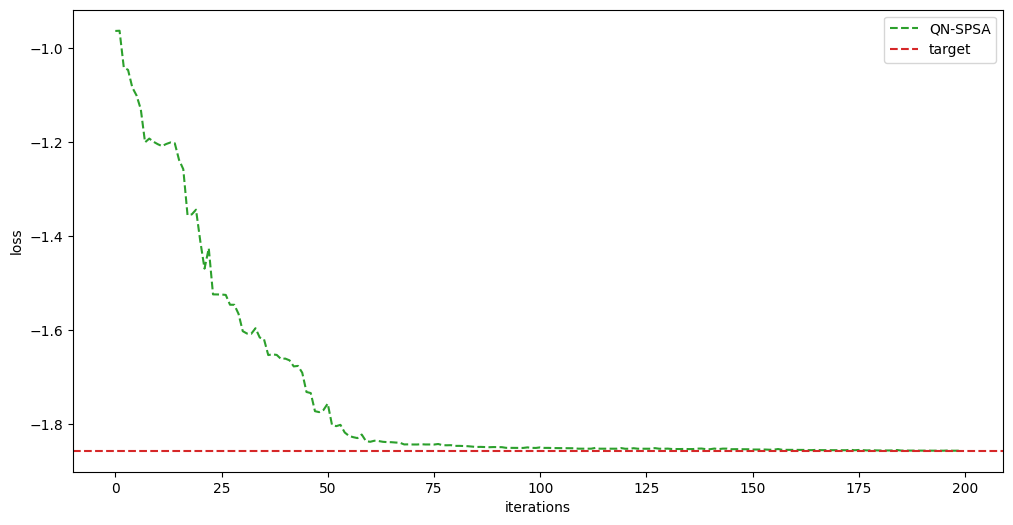

In [60]:
H2_fermionic_hamiltonian, H2_num_particles, H2_num_spin_orbitals, H2_qubit_op, H2_qubit_converter, H2_ground_state = \
                solve_ground_state(
                    H2_info_dict,
                    mapper_name="Parity",
                    two_qubit_reduction=True,
                    z2symmetry_reduction=None,
                    label='QN-SPSA',
                    do_plot_loss=True,
                    target=-1.857274810366,
                    maxiter=200,
                    learning_rate=0.01,
                    perturbation=0.7,
                    show_VQE=True,
                    name_solver='vqe_tl_QNSPSA_solver')

### Computing the BOPES

Number of particles: (1, 1)
Number of spin orbitals: 4
 
Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 5
SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ', 'XX'],
              coeffs=[-1.05237325+0.j,  0.39793742+0.j, -0.39793742+0.j, -0.0112801 +0.j,
  0.1809312 +0.j])

solve_ground_state - num_qubits: 2
 
PySCF restricted HF (RHF) converged ground-state energy: -1.116998996754
Iteration, Energy, Error
0:         -1.1128 0.0074
1:         -1.1420 0.0072
2:         -1.1417 0.0052
3:         -1.1553 0.0056
PyQMC Monte Carlo converged ground-state energy: -1.155336570864, error: 0.0056
Number of particles: (1, 1)
Number of spin orbitals: 4
 
Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 5
SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ', 'XX'],
              coeffs=[-0.67580549+0.j,  0.88898635+0.j, -0.88898635+0.j, -0.01351353+0.j,
  0.1588593 +0.j])

solve_ground_state - num_qubits: 2
 
PySCF restricted HF (RHF) converged ground-s

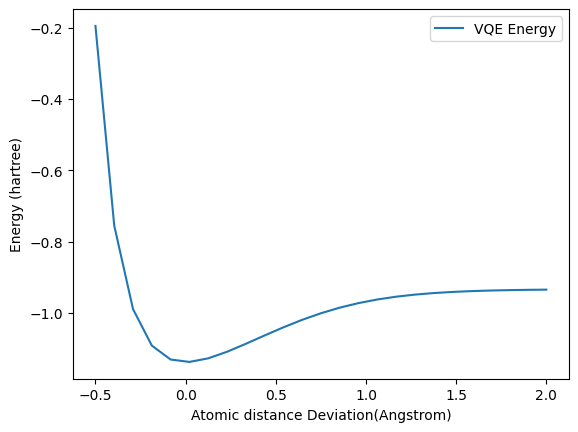

In [61]:
perturbation_steps = np.linspace(-0.5, 2, 25) # 25 equally spaced points from -0.2 to 4, inclusive.
H2_s_fermionic_hamiltonian, H2_s_num_particles, H2_s_num_spin_orbitals, H2_s_qubit_op, H2_s_qubit_converter, H2_s_ground_state = \
                  solve_ground_state(
                      H2_info_dict,
                      mapper_name="Parity",
                      two_qubit_reduction=True,
                      z2symmetry_reduction=None,
                      plot_bopes = True,
                      perturbation_steps=perturbation_steps,
                      show_VQE=False,
                      name_solver = 'NumPy exact solver')

## 5.2.2. Lithium hydride molecule

In [62]:
LiH_atoms = ["Li", "H"]
LiH_coords = [(0.0, 0.0, 0.0), (0.0, 0.0, 1.5474)]
LiH_charge = 0
LiH_multiplicity = 1
LiH_atom_pair=(1,0)
LiH_info_dict={'atoms':LiH_atoms, 'coords':LiH_coords, 'charge':LiH_charge, 'multiplicity':LiH_multiplicity, 'atom_pair':LiH_atom_pair}

LiH_moleculeinfo = MoleculeInfo(LiH_atoms, LiH_coords, charge=LiH_charge, multiplicity=LiH_multiplicity)

### Solving for the Ground-state

In [63]:
LiH_fermionic_hamiltonian, LiH_num_particles, LiH_num_spin_orbitals, LiH_qubit_op, LiH_qubit_converter, LiH_ground_state = \
                  solve_ground_state(
                      LiH_info_dict,
                      mapper_name="Parity",
                      freeze_core=FreezeCoreTransformer(freeze_core=True, remove_orbitals=[4, 3]),
                      two_qubit_reduction=True,
                      z2symmetry_reduction="auto",
                      n_ancillae=10,
                      do_run_qpe=True,
                      show_Ferm_op=True,
                      show_VQE=True,
                      name_solver='NumPy exact solver')

Fermionic Hamiltonian operator
Fermionic Operator
number spin orbitals=6, number terms=342
  -0.7806641137752405 * ( +_0 -_0 )
+ 0.04770212743642579 * ( +_0 -_1 )
+ -0.1295811879600755 * ( +_0 -_2 )
+ 0.047702127436425726 * ( +_1 -_0 )
+ -0.3590972946155812 * ( +_1 -_1 )
+ 0.06823802873508782 * ( +_1 -_2 )
+ -0.12958118796007576 * ( +_2 -_0 )
+ 0.06823802873508766 * ( +_2 -_1 )
+ -0.2261711485620651 * ( +_2 -_2 )
+ -0.7806641137752405 * ( +_3 -_3 )
+ 0.04770212743642579 * ( +_3 -_4 )
+ -0.1295811879600755 * ( +_3 -_5 )
+ 0.047702127436425726 * ( +_4 -_3 )
+ -0.3590972946155812 * ( +_4 -_4 )
+ 0.06823802873508782 * ( +_4 -_5 )
+ -0.12958118796007576 * ( +_5 -_3 )
+ 0.06823802873508766 * ( +_5 -_4 )
+ -0.2261711485620651 * ( +_5 -_5 )
...
Number of particles: (1, 1)
Number of spin orbitals: 6
 
Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 100
SparsePauliOp(['IIII', 'IIIZ', 'IIZX', 'IIIX', 'IIXX', 'IIYY', 'IIZZ', 'IIXZ', 'IIXI', 'IIZI', 'IZII', 'ZXI

/home/alain/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/home/alain/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)



Chosen candidate: k=-2, alt_plus
Chosen energy:   -7.965910 Ha

Measured phase: 0.12890625
Ground state energy from QPE: -7.965910 Ha
 
Running the VQE using the NumPy exact solver
run_vqe - main_operator.num_qubits: 4
Elapsed time: 0:00:00.169945

=== GROUND STATE ENERGY ===
 
* Electronic ground state energy (Hartree): -8.907396311316
  - computed part:      -1.088706015729
  - FreezeCoreTransformer extracted energy part: -7.818690295587
~ Nuclear repulsion energy (Hartree): 1.025934879643
> Total ground state energy (Hartree): -7.881461431673
 
=== MEASURED OBSERVABLES ===
 
  0:  # Particles: 2.000 S: 0.000 S^2: 0.000 M: 0.000
 
=== DIPOLE MOMENTS ===
 
~ Nuclear dipole moment (a.u.): [0.0  0.0  2.92416221]
 
  0: 
  * Electronic dipole moment (a.u.): [0.0  0.0  4.763008894043]
    - computed part:      [0.0  0.0  4.766955752366]
    - FreezeCoreTransformer extracted energy part: [0.0  0.0  -0.003946858323]
  > Dipole moment (a.u.): [0.0  0.0  -1.838846684043]  Total: 1.8388466840

In [64]:
LiH_fermionic_hamiltonian, LiH_num_particles, LiH_num_spin_orbitals, LiH_qubit_op, LiH_qubit_converter, LiH_ground_state = \
                  solve_ground_state(
                      LiH_info_dict,
                      mapper_name="Parity",
                      freeze_core=FreezeCoreTransformer(freeze_core=True, remove_orbitals=[4, 3]),
                      two_qubit_reduction=True,
                      z2symmetry_reduction="auto",
                      show_VQE=True,
                      name_solver = 'vqe_tl_solver')

Number of particles: (1, 1)
Number of spin orbitals: 6
 
Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 100
SparsePauliOp(['IIII', 'IIIZ', 'IIZX', 'IIIX', 'IIXX', 'IIYY', 'IIZZ', 'IIXZ', 'IIXI', 'IIZI', 'IZII', 'ZXII', 'IXII', 'XXII', 'YYII', 'ZZII', 'XZII', 'XIII', 'ZIII', 'IZIZ'],
              coeffs=[-0.20316606+0.j, -0.09275995+0.j, -0.00294114+0.j,  0.00294114+0.j,
 -0.0007428 +0.j,  0.0007428 +0.j, -0.21188984+0.j,  0.01938941+0.j,
  0.01938941+0.j,  0.36525869+0.j,  0.09275995+0.j,  0.00294114+0.j,
  0.00294114+0.j, -0.0007428 +0.j,  0.0007428 +0.j, -0.21188984+0.j,
 -0.01938941+0.j,  0.01938941+0.j, -0.36525869+0.j, -0.12274244+0.j])

solve_ground_state - num_qubits: 4
 
PySCF restricted HF (RHF) converged ground-state energy: -7.863113882796
Iteration, Energy, Error
0:         -7.7079 0.0511
1:         -7.8859 0.0393
2:         -8.1481 0.0418
3:         -7.7607 0.0356
PyQMC Monte Carlo converged ground-state energy: -7.760695159057, error

Number of particles: (1, 1)
Number of spin orbitals: 6
 
Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 100
SparsePauliOp(['IIII', 'IIIZ', 'IIZX', 'IIIX', 'IIXX', 'IIYY', 'IIZZ', 'IIXZ', 'IIXI', 'IIZI', 'IZII', 'ZXII', 'IXII', 'XXII', 'YYII', 'ZZII', 'XZII', 'XIII', 'ZIII', 'IZIZ'],
              coeffs=[-0.20316606+0.j, -0.09275995+0.j, -0.00294114+0.j,  0.00294114+0.j,
 -0.0007428 +0.j,  0.0007428 +0.j, -0.21188984+0.j,  0.01938941+0.j,
  0.01938941+0.j,  0.36525869+0.j,  0.09275995+0.j,  0.00294114+0.j,
  0.00294114+0.j, -0.0007428 +0.j,  0.0007428 +0.j, -0.21188984+0.j,
 -0.01938941+0.j,  0.01938941+0.j, -0.36525869+0.j, -0.12274244+0.j])

solve_ground_state - num_qubits: 4
 
PySCF restricted HF (RHF) converged ground-state energy: -7.863113882796
Iteration, Energy, Error
0:         -7.7990 0.0397
1:         -7.8700 0.0393
2:         -7.8156 0.0479
3:         -7.9622 0.0360
PyQMC Monte Carlo converged ground-state energy: -7.962241075466, error

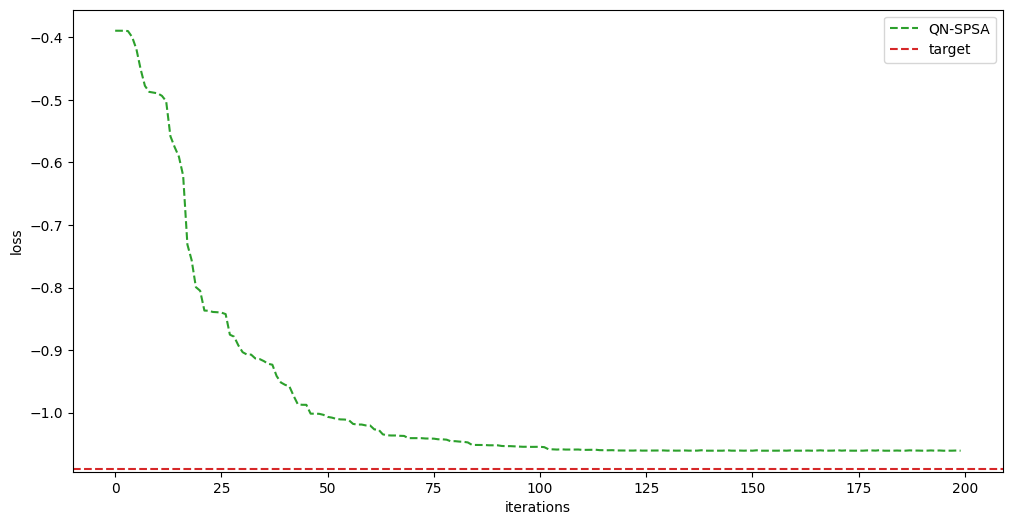

In [65]:
LiH_fermionic_hamiltonian, LiH_num_particles, LiH_num_spin_orbitals, LiH_qubit_op, LiH_qubit_converter, LiH_ground_state = \
            solve_ground_state(
                LiH_info_dict,
                mapper_name="Parity",
                freeze_core=FreezeCoreTransformer(freeze_core=True, remove_orbitals=[4, 3]),
                two_qubit_reduction=True,
                z2symmetry_reduction="auto",
                label='QN-SPSA',
                target=-1.09,
                do_plot_loss=True,
                maxiter=200,
                learning_rate=7.0e-3,
                perturbation=1.0e-3,
                show_VQE=True,
                name_solver='vqe_tl_QNSPSA_solver')

### Computing the Born-Oppenheimer Potential Energy Surface (BOPES)

Number of particles: (1, 1)
Number of spin orbitals: 6
 
Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 100
SparsePauliOp(['IIII', 'IIIZ', 'IIZX', 'IIIX', 'IIXX', 'IIYY', 'IIZZ', 'IIXZ', 'IIXI', 'IIZI', 'IZII', 'ZXII', 'IXII', 'XXII', 'YYII', 'ZZII', 'XZII', 'XIII', 'ZIII', 'IZIZ'],
              coeffs=[-0.20316606+0.j, -0.09275995+0.j, -0.00294114+0.j,  0.00294114+0.j,
 -0.0007428 +0.j,  0.0007428 +0.j, -0.21188984+0.j,  0.01938941+0.j,
  0.01938941+0.j,  0.36525869+0.j,  0.09275995+0.j,  0.00294114+0.j,
  0.00294114+0.j, -0.0007428 +0.j,  0.0007428 +0.j, -0.21188984+0.j,
 -0.01938941+0.j,  0.01938941+0.j, -0.36525869+0.j, -0.12274244+0.j])

solve_ground_state - num_qubits: 4
 
PySCF restricted HF (RHF) converged ground-state energy: -7.863113882796
Iteration, Energy, Error
0:         -7.7607 0.0486
1:         -8.1015 0.0425
2:         -7.9795 0.0274
3:         -8.2048 0.0279
PyQMC Monte Carlo converged ground-state energy: -8.204787394742, error

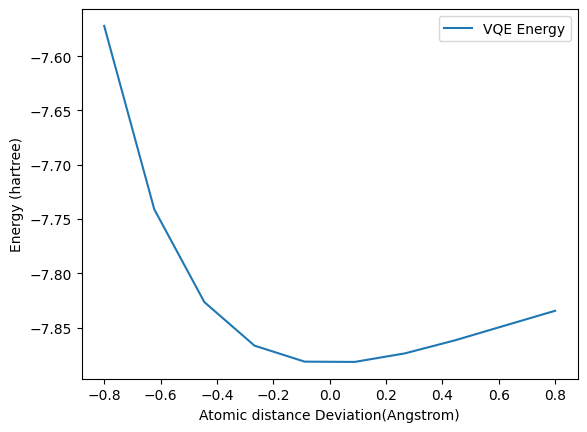

In [66]:
perturbation_steps = np.linspace(-0.8, 0.8, 10) # 10 equally spaced points from -0.8 to 0.8, inclusive.
LiH_s_fermionic_hamiltonian, LiH_s_num_particles, LiH_s_num_spin_orbitals, LiH_s_qubit_op, LiH_s_qubit_converter, LiH_s_ground_state = \
                solve_ground_state(
                    LiH_info_dict,
                    mapper_name="Parity",
                    freeze_core=FreezeCoreTransformer(freeze_core=True, remove_orbitals=[4, 3]),
                    two_qubit_reduction=True,
                    z2symmetry_reduction="auto",
                    name_solver='NumPy exact solver',
                    plot_bopes=True,
                    show_VQE=False,
                    perturbation_steps=perturbation_steps)

## 5.2.3. Macro molecule

In [67]:
macro_ASE = Atoms('ONCHHHC', [(1.1280, 0.2091, 0.0000), 
                          (-1.1878, 0.1791, 0.0000), 
                          (0.0598, -0.3882, 0.0000),
                          (-1.3085, 1.1864, 0.0001),
                          (-2.0305, -0.3861, -0.0001),
                          (-0.0014, -1.4883, -0.0001),
                          (-0.1805, 1.3955, 0.0000)])

In [68]:
view(macro_ASE, viewer='x3d')

In [69]:
M_atoms = ["O", "N","C","H","H","H","C"]
M_coords = [(1.1280, 0.2091, 0.0000), 
                    (-1.1878, 0.1791, 0.0000),
                    (0.0598, -0.3882, 0.0000),
                    (-1.3085, 1.1864, 0.0001),
                    (-2.0305, -0.3861, -0.0001),
                    (-0.0014, -1.4883, -0.0001),
                    (-0.1805, 1.3955, 0.0000)]
M_charge = 0
M_multiplicity = 1
M_atom_pair=(6, 1)
M_info_dict={'atoms':M_atoms, 'coords':M_coords, 'charge':M_charge, 'multiplicity':M_multiplicity, 'atom_pair':M_atom_pair}

macromoleculeinfo = MoleculeInfo(M_atoms, M_coords, charge=M_charge, multiplicity=M_multiplicity)

### Solving for the Ground-state

In [70]:
print("Macro molecule")
print("Using the ParityMapper with two_qubit_reduction=True to eliminate two qubits")
print("Parameters ActiveSpaceTransformer(num_electrons=2, num_molecular_orbitals=2)")
print("Setting z2symmetry_reduction=\"auto\"")

Macro molecule
Using the ParityMapper with two_qubit_reduction=True to eliminate two qubits
Parameters ActiveSpaceTransformer(num_electrons=2, num_molecular_orbitals=2)
Setting z2symmetry_reduction="auto"


In [71]:
macro_fermionic_hamiltonian, macro_particle_num_particles, macro_particle_num_spin_orbitals, macro_qubit_op, macro_qubit_converter, macro_ground_state = \
                  solve_ground_state(
                      M_info_dict,
                      mapper_name="Parity",
                      num_electrons=2,
                      num_spatial_orbitals=2,
                      two_qubit_reduction=True,
                      z2symmetry_reduction="auto",
                      name_solver='NumPy exact solver',
                      show_Ferm_op=True,
                      show_VQE=True,
                      pyqmc=False)

Fermionic Hamiltonian operator
Fermionic Operator
number spin orbitals=4, number terms=72
  -0.7480531938936814 * ( +_0 -_0 )
+ -0.05107721100435583 * ( +_0 -_1 )
+ -0.051077211004356 * ( +_1 -_0 )
+ -0.32719067439050686 * ( +_1 -_1 )
+ -0.7480531938936814 * ( +_2 -_2 )
+ -0.05107721100435583 * ( +_2 -_3 )
+ -0.051077211004356 * ( +_3 -_2 )
+ -0.32719067439050686 * ( +_3 -_3 )
+ 0.30591799250135415 * ( +_0 +_0 -_0 -_0 )
+ 0.025538510234196243 * ( +_0 +_0 -_1 -_0 )
+ 0.025538510234196243 * ( +_0 +_1 -_0 -_0 )
+ 0.1514357335105117 * ( +_0 +_1 -_1 -_0 )
+ 0.30591799250135415 * ( +_0 +_2 -_2 -_0 )
+ 0.025538510234196243 * ( +_0 +_2 -_3 -_0 )
+ 0.025538510234196243 * ( +_0 +_3 -_2 -_0 )
+ 0.1514357335105117 * ( +_0 +_3 -_3 -_0 )
+ 0.025538510234196243 * ( +_0 +_0 -_0 -_1 )
+ 0.013459866360415058 * ( +_0 +_0 -_1 -_1 )
...
Number of particles: (1, 1)
Number of spin orbitals: 4
 
Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 9
SparsePauliOp(['II', 'IZ', '

### Computing the BOPES

Number of particles: (1, 1)
Number of spin orbitals: 4
 
Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 9
SparsePauliOp(['II', 'IZ', 'IX', 'ZI', 'XI', 'ZZ', 'XZ', 'ZX', 'XX'],
              coeffs=[-0.64100287+0.j,  0.18731853+0.j, -0.05017307+0.j, -0.18731853+0.j,
 -0.05017307+0.j, -0.13136953+0.j, -0.05017288+0.j,  0.05017288+0.j,
  0.02691973+0.j])

solve_ground_state - num_qubits: 2
 
PySCF restricted HF (RHF) converged ground-state energy: -203.543863584135
Number of particles: (1, 1)
Number of spin orbitals: 4
 
Qubit Hamiltonian operator
Parity transformation 
Number of items in the Pauli list: 9
SparsePauliOp(['II', 'IZ', 'IX', 'ZI', 'XI', 'ZZ', 'XZ', 'ZX', 'XX'],
              coeffs=[-5.44980025e-01+0.j,  9.95504266e-02+0.j, -4.02075826e-05+0.j,
 -9.95504266e-02+0.j, -4.02075826e-05+0.j, -8.79735904e-02+0.j,
 -3.79013217e-05+0.j,  3.79013217e-05+0.j,  5.18395205e-03+0.j])

solve_ground_state - num_qubits: 2
 
PySCF restricted HF (RHF) con

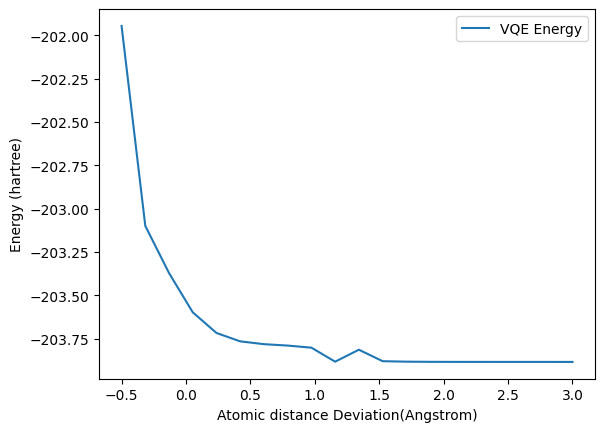

In [72]:
perturbation_steps = np.linspace(-0.5, 3, 20) # 20 equally spaced points from -0.5 to 3, inclusive.
macro_fermionic_hamiltonian, macro_particle_num_particles, macro_particle_num_spin_orbitals, macro_qubit_op, macro_qubit_converter, macro_ground_state = \
                  solve_ground_state(
                      M_info_dict,
                      mapper_name="Parity",
                      num_electrons=2,
                      num_spatial_orbitals=2,
                      two_qubit_reduction=True,
                      z2symmetry_reduction="auto",
                      name_solver='NumPy exact solver',
                      pyqmc=False,
                      plot_bopes=True,
                      show_VQE=False,
                      perturbation_steps=perturbation_steps)

# Summary

# Questions

In [73]:
#@title Enter your answer Yes, No or ? for a solution, then execute cell.
answer = "" #@param {type:"string"}
solution = "Yes"
if answer == solution:
    print("Correct")
elif answer == '?':
    print(solution)
else:
    print("Incorrect, please try again")

Incorrect, please try again


In [74]:
#@title Enter your answer True, False or ? for a solution, then execute cell.
answer = "" #@param {type:"string"}
solution = "True"
if answer == solution:
    print("Correct")
elif answer == '?':
    print(solution)
else:
    print("Incorrect, please try again")

Incorrect, please try again


In [75]:
#@title Enter your answer True, False or ? for a solution, then execute cell.
answer = "" #@param {type:"string"}
solution = "False"
if answer == solution:
    print("Correct")
elif answer == '?':
    print(solution)
else:
    print("Incorrect, please try again")

Incorrect, please try again


# References
[ASE_0] Atomic Simulation Environment (ASE), https://wiki.fysik.dtu.dk/ase/index.html

[H5py] Quick Start Guide, https://docs.h5py.org/en/stable/quick.html 

[Loredo_Qiskit] Robert Loredo, Chapter 3: Introducing and Installing Qiskit. Learn Quantum Computing with Python and IBM Quantum, Packt Publishing, 2025. ISBN 978-1803244808, https://www.amazon.fr/Learn-Quantum-Computing-Python-IBM/dp/1803244801/

[NumPy] NumPy: the absolute basics for beginners, https://numpy.org/doc/stable/user/absolute_beginners.html

[PyQMC] PyQMC, a python module that implements real-space quantum Monte Carlo techniques, https://github.com/WagnerGroup/pyqmc 

[PySCF] The Python-based Simulations of Chemistry Framework (PySCF), https://pyscf.org/

[Qiskit] Qiskit, https://qiskit.org/

[Qiskit_Aer_1] Qiskit Aer documentation, https://qiskit.github.io/qiskit-aer/ 

[Qiskit_Nat_0] Qiskit_Nature, https://github.com/Qiskit/qiskit-nature/blob/main/README.md 

[Qiskit_Nature] Qiskit Nature overview, Qiskit Nature 0.7.2, https://qiskit-community.github.io/qiskit-nature/

[QuTiP] QuTiP, Plotting on the Bloch Sphere, https://qutip.readthedocs.io/en/qutip-5.0.x/guide/guide-bloch.html

[SciPy] Statistical functions (scipy.stats), https://projects.scipy.org/getting-started.html

## Qiskit packages versions

In [78]:
import qiskit
import qiskit_aer

print(f'Qiskit: {qiskit.__version__}')
print(f"Qiskit Aer version: {qiskit_aer.__version__}")

Qiskit: 2.3.0
Qiskit IBM Runtime: 0.45.1
Qiskit Aer version: 0.17.2


## Qiskit Nature

In [79]:
import qiskit_nature
print(f"Qiskit Nature version: {qiskit_nature.__version__}")

Qiskit Nature version: 0.7.2


## Qiskit Algorithms

In [80]:
import qiskit_algorithms
print(f"Qiskit Algorithms version: {qiskit_algorithms.__version__}")

Qiskit Algorithms version: 0.4.0


## Python

In [81]:
%%bash
which python
python --version

/home/alain/miniconda3/bin/python
Python 3.13.11
